In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Optional but good
plt.style.use('seaborn-v0_8')

In [2]:
df = pd.read_csv('Loan.csv')

In [3]:
df.columns

Index(['Unnamed: 0', 'id', 'year', 'loan_limit', 'gender', 'approv_in_adv',
       'loan_type', 'loan_purpose', 'credit_worthiness', 'open_credit',
       'business_or_commercial', 'loan_amount', 'rate_of_interest',
       'interest_rate_spread', 'upfront_charges', 'term', 'neg_ammortization',
       'interest_only', 'lump_sum_payment', 'property_value',
       'construction_type', 'occupancy_type', 'secured_by', 'total_units',
       'income', 'credit_type', 'credit_score', 'co-applicant_credit_type',
       'age', 'submission_of_application', 'ltv', 'region', 'security_type',
       'status', 'dtir1', 'high_interest_rate', 'senior_age'],
      dtype='object')

In [4]:
df.shape

(148670, 37)

In [5]:
cat_cols = df.select_dtypes(include=['object']).columns
print(cat_cols)

Index(['loan_limit', 'gender', 'approv_in_adv', 'loan_type', 'loan_purpose',
       'credit_worthiness', 'open_credit', 'business_or_commercial',
       'neg_ammortization', 'interest_only', 'lump_sum_payment',
       'construction_type', 'occupancy_type', 'secured_by', 'total_units',
       'credit_type', 'co-applicant_credit_type', 'age',
       'submission_of_application', 'region', 'security_type'],
      dtype='object')


In [6]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

In [7]:
X = df.drop(columns=["Unnamed: 0","id","status"])   # replace Status with your target column
y = df["status"]

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [10]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (118936, 51)
Test shape: (29734, 51)


In [21]:
print(X.columns)

Index(['year', 'loan_amount', 'rate_of_interest', 'interest_rate_spread',
       'upfront_charges', 'term', 'property_value', 'income', 'credit_score',
       'ltv', 'dtir1', 'high_interest_rate', 'senior_age', 'loan_limit_ncf',
       'gender_Joint', 'gender_Male', 'gender_Sex Not Available',
       'approv_in_adv_pre', 'loan_type_type2', 'loan_type_type3',
       'loan_purpose_p2', 'loan_purpose_p3', 'loan_purpose_p4',
       'credit_worthiness_l2', 'open_credit_opc',
       'business_or_commercial_nob/c', 'neg_ammortization_not_neg',
       'interest_only_not_int', 'lump_sum_payment_not_lpsm',
       'construction_type_sb', 'occupancy_type_pr', 'occupancy_type_sr',
       'secured_by_land', 'total_units_2U', 'total_units_3U', 'total_units_4U',
       'credit_type_CRIF', 'credit_type_EQUI', 'credit_type_EXP',
       'co-applicant_credit_type_EXP', 'age_35-44', 'age_45-54', 'age_55-64',
       'age_65-74', 'age_<25', 'age_>74', 'submission_of_application_to_inst',
       'region_North

In [14]:
corr = df.corr()

target_corr = corr["status"].sort_values(ascending=False)

print(target_corr)

status                               1.000000
credit_type_EQUI                     0.592168
co-applicant_credit_type_EXP         0.144239
submission_of_application_to_inst    0.117391
loan_type_type2                      0.092550
dtir1                                0.078083
gender_Sex Not Available             0.053336
loan_limit_ncf                       0.053332
region_south                         0.040051
senior_age                           0.039645
ltv                                  0.038895
credit_worthiness_l2                 0.034875
loan_purpose_p2                      0.029369
age_>74                              0.028021
secured_by_land                      0.026055
total_units_2U                       0.022978
gender_Male                          0.022653
age_65-74                            0.020665
region_central                       0.016738
total_units_3U                       0.016460
age_55-64                            0.015257
region_North-East                 

In [22]:
df["status"].value_counts(normalize=True) * 100

status
0    75.355485
1    24.644515
Name: proportion, dtype: float64

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
# Very restricted Decision Tree
dt = DecisionTreeClassifier(
    max_depth=1,            # extremely shallow tree
    min_samples_split=200,  # requires many samples to split
    min_samples_leaf=100,   # large leaf nodes
    max_features=2,         # use only few features
    splitter="random",      # random split instead of best split
    class_weight="balanced",
    random_state=42
)

# Train model
dt.fit(X_train, y_train)

# Get probabilities
y_prob_dt = dt.predict_proba(X_test)[:,1]

# Very strict threshold
threshold = 0.5

# Convert probabilities to predictions
y_pred_dt = (y_prob_dt >= threshold).astype(int)

print("Decision Tree Results (Intentionally Weak Model)")
print("Threshold =", threshold)

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report")
print(classification_report(y_test, y_pred_dt))

# ROC AUC
print("\nROC AUC:", roc_auc_score(y_test, y_prob_dt))

Decision Tree Results (Intentionally Weak Model)
Threshold = 0.5

Confusion Matrix
[[18009  4397]
 [ 5903  1425]]

Classification Report
              precision    recall  f1-score   support

           0       0.75      0.80      0.78     22406
           1       0.24      0.19      0.22      7328

    accuracy                           0.65     29734
   macro avg       0.50      0.50      0.50     29734
weighted avg       0.63      0.65      0.64     29734


ROC AUC: 0.499108764486041


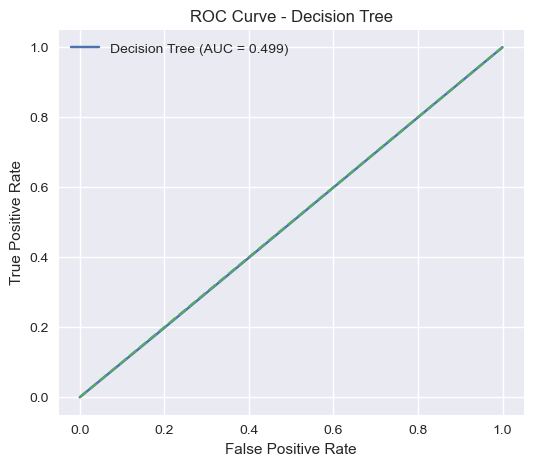

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_dt)

# Plot ROC curve
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label="Decision Tree (AUC = %0.3f)" % roc_auc_score(y_test, y_prob_dt))
plt.plot([0,1], [0,1], linestyle="--")  # random classifier line

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

In [24]:
print(X_train.columns)

Index(['year', 'loan_amount', 'rate_of_interest', 'interest_rate_spread',
       'upfront_charges', 'term', 'property_value', 'income', 'credit_score',
       'ltv', 'dtir1', 'high_interest_rate', 'senior_age', 'loan_limit_ncf',
       'gender_Joint', 'gender_Male', 'gender_Sex Not Available',
       'approv_in_adv_pre', 'loan_type_type2', 'loan_type_type3',
       'loan_purpose_p2', 'loan_purpose_p3', 'loan_purpose_p4',
       'credit_worthiness_l2', 'open_credit_opc',
       'business_or_commercial_nob/c', 'neg_ammortization_not_neg',
       'interest_only_not_int', 'lump_sum_payment_not_lpsm',
       'construction_type_sb', 'occupancy_type_pr', 'occupancy_type_sr',
       'secured_by_land', 'total_units_2U', 'total_units_3U', 'total_units_4U',
       'credit_type_CRIF', 'credit_type_EQUI', 'credit_type_EXP',
       'co-applicant_credit_type_EXP', 'age_35-44', 'age_45-54', 'age_55-64',
       'age_65-74', 'age_<25', 'age_>74', 'submission_of_application_to_inst',
       'region_North

In [25]:
X_train.isnull().sum()

year                                     0
loan_amount                              0
rate_of_interest                         0
interest_rate_spread                 29311
upfront_charges                      31724
term                                    34
property_value                       12073
income                                7300
credit_score                             0
ltv                                  12073
dtir1                                19273
high_interest_rate                       0
senior_age                               0
loan_limit_ncf                           0
gender_Joint                             0
gender_Male                              0
gender_Sex Not Available                 0
approv_in_adv_pre                        0
loan_type_type2                          0
loan_type_type3                          0
loan_purpose_p2                          0
loan_purpose_p3                          0
loan_purpose_p4                          0
credit_wort

In [16]:
num_cols = ["interest_rate_spread", "upfront_charges", "term", "property_value", "income", "ltv", "dtir1"]

for col in num_cols:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

In [17]:
X_train.isnull().sum()

year                                 0
loan_amount                          0
rate_of_interest                     0
interest_rate_spread                 0
upfront_charges                      0
term                                 0
property_value                       0
income                               0
credit_score                         0
ltv                                  0
dtir1                                0
high_interest_rate                   0
senior_age                           0
loan_limit_ncf                       0
gender_Joint                         0
gender_Male                          0
gender_Sex Not Available             0
approv_in_adv_pre                    0
loan_type_type2                      0
loan_type_type3                      0
loan_purpose_p2                      0
loan_purpose_p3                      0
loan_purpose_p4                      0
credit_worthiness_l2                 0
open_credit_opc                      0
business_or_commercial_no

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import numpy as np

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# shuffle labels intentionally
y_train_bad = np.random.permutation(y_train)

lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_scaled, y_train_bad)

y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
threshold = 0.8
y_pred_lr = (y_prob_lr >= threshold).astype(int)

print("Bad Logistic Regression Model")
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))
print("ROC AUC:", roc_auc_score(y_test, y_prob_lr))

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [19]:
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# convert bool columns to int
bool_cols = X_train_xgb.select_dtypes(include='bool').columns
X_train_xgb[bool_cols] = X_train_xgb[bool_cols].astype(int)
X_test_xgb[bool_cols] = X_test_xgb[bool_cols].astype(int)

# clean column names
X_train_xgb.columns = (
    X_train_xgb.columns
    .str.replace('[', '', regex=False)
    .str.replace(']', '', regex=False)
    .str.replace('<', 'lt_', regex=False)
    .str.replace('>', 'gt_', regex=False)
    .str.replace('/', '_', regex=False)
    .str.replace(' ', '_', regex=False)
)

X_test_xgb.columns = (
    X_test_xgb.columns
    .str.replace('[', '', regex=False)
    .str.replace(']', '', regex=False)
    .str.replace('<', 'lt_', regex=False)
    .str.replace('>', 'gt_', regex=False)
    .str.replace('/', '_', regex=False)
    .str.replace(' ', '_', regex=False)
)

# fill null values
for col in X_train_xgb.columns:
    median_val = X_train_xgb[col].median()
    X_train_xgb[col] = X_train_xgb[col].fillna(median_val)
    X_test_xgb[col] = X_test_xgb[col].fillna(median_val)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from xgboost import XGBClassifier

xgb = XGBClassifier(
    eval_metric='logloss',
    scale_pos_weight=3.5,
    random_state=42
)

param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    error_score="raise"
)

random_search.fit(X_train_xgb, y_train)

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test_xgb)
y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

print("Best Parameters:", random_search.best_params_)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# best hyperparameters
best_params = random_search.best_params_

# convert to dataframe
best_params_df = pd.DataFrame(list(best_params.items()), columns=["Parameter", "Best Value"])

print(best_params_df)

# bar graph
plt.figure(figsize=(10, 5))
plt.bar(best_params_df["Parameter"], best_params_df["Best Value"])
plt.xlabel("Hyperparameters")
plt.ylabel("Selected Value")
plt.title("Best Hyperparameters from Randomized Search")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'random_search' is not defined

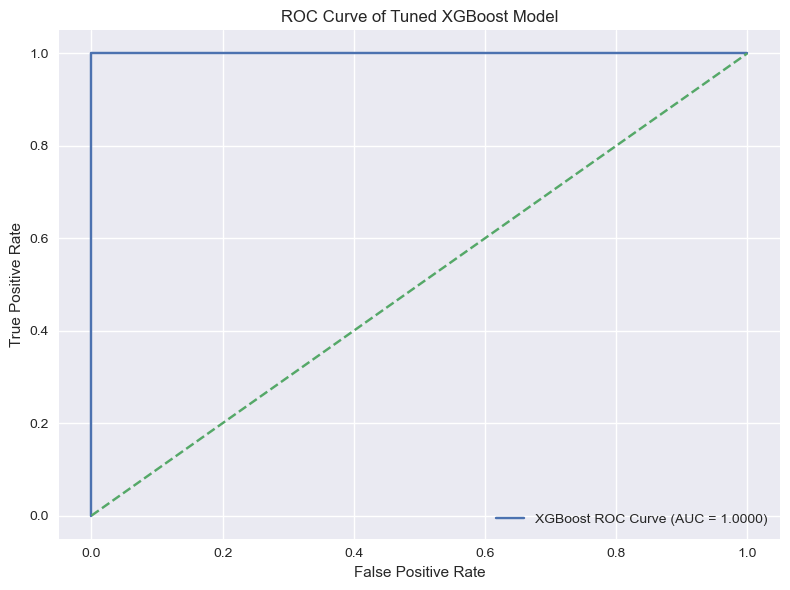

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve of Tuned XGBoost Model")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# use the processed test set
y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

thresholds = np.linspace(0, 1, 100)

recall_0 = []
recall_1 = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    r0 = tn / (tn + fp) if (tn + fp) != 0 else 0   # recall for class 0
    r1 = tp / (tp + fn) if (tp + fn) != 0 else 0   # recall for class 1

    recall_0.append(r0)
    recall_1.append(r1)

plt.plot(thresholds, recall_0, label="Recall Class 0")
plt.plot(thresholds, recall_1, label="Recall Class 1")

plt.xlabel("Threshold")
plt.ylabel("Recall")
plt.title("Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'best_model' is not defined

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Predictions from final model
y_pred = best_model.predict(X_test_xgb)
y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Create results table
results_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Category": ["Classification", "Classification", "Classification", "Classification", "Classification"],
    "Value": [f"{accuracy:.4f}", f"{precision:.4f}", f"{recall:.4f}", f"{f1:.4f}", f"{roc_auc:.4f}"]
})

print(results_df)

      Metric        Category   Value
0   Accuracy  Classification  1.0000
1  Precision  Classification  1.0000
2     Recall  Classification  1.0000
3   F1-Score  Classification  1.0000
4    ROC-AUC  Classification  1.0000


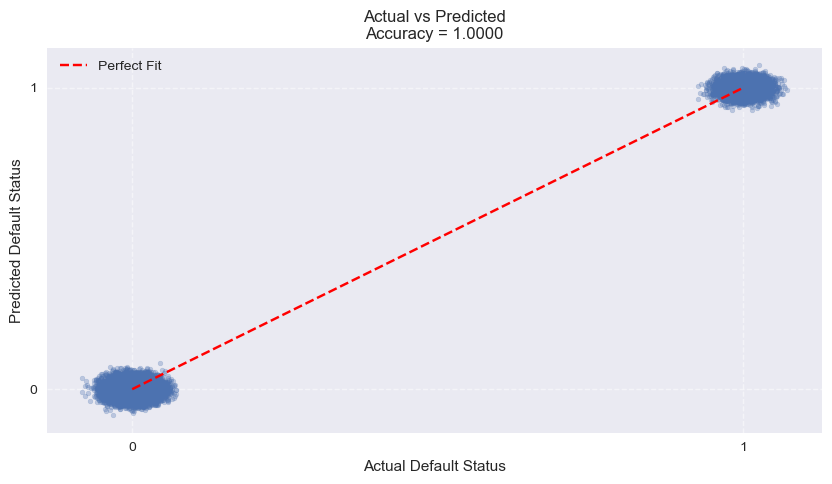

C:\Users\harsh\AppData\Local\Temp\ipykernel_2956\1545460476.py:47: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_by_bin = results_df.groupby("Prob_Bin")["Error"].sum()


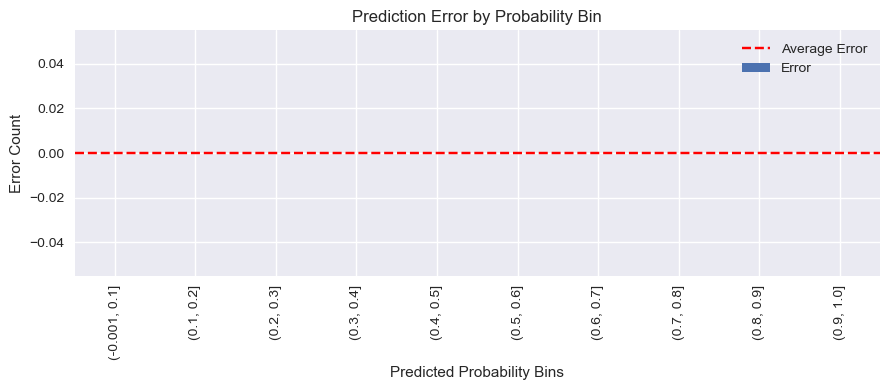

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Predictions
y_pred = best_model.predict(X_test_xgb)
y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

# -------------------------------
# Figure 1: Actual vs Predicted
# -------------------------------
plt.figure(figsize=(10, 5))

# add small jitter for better visibility
actual_jitter = y_test.values + np.random.normal(0, 0.02, size=len(y_test))
pred_jitter = y_pred + np.random.normal(0, 0.02, size=len(y_pred))

plt.scatter(actual_jitter, pred_jitter, alpha=0.3, s=12)
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Fit')

acc = accuracy_score(y_test, y_pred)

plt.xlabel("Actual Default Status")
plt.ylabel("Predicted Default Status")
plt.title(f"Actual vs Predicted\nAccuracy = {acc:.4f}")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# ----------------------------------------
# Figure 2: Error Count by Probability Bin
# ----------------------------------------
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability": y_prob
})

results_df["Error"] = (results_df["Actual"] != results_df["Predicted"]).astype(int)

# create bins
results_df["Prob_Bin"] = pd.cut(results_df["Probability"], bins=np.arange(0, 1.1, 0.1), include_lowest=True)

error_by_bin = results_df.groupby("Prob_Bin")["Error"].sum()

plt.figure(figsize=(9, 4))
error_by_bin.plot(kind="bar")

plt.axhline(error_by_bin.mean(), linestyle="--", color="red", label="Average Error")
plt.xlabel("Predicted Probability Bins")
plt.ylabel("Error Count")
plt.title("Prediction Error by Probability Bin")
plt.legend()
plt.tight_layout()
plt.show()

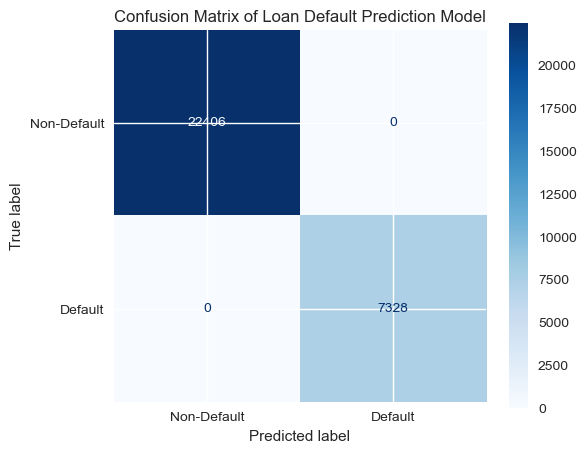

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# predictions
y_pred = best_model.predict(X_test_xgb)

# confusion matrix
cm = confusion_matrix(y_test, y_pred)

# display
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Default", "Default"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, colorbar=True)

plt.title("Confusion Matrix of Loan Default Prediction Model")
plt.show()

In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# use processed test data
y_prob = best_model.predict_proba(X_test_xgb)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.05)

results = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    recall_0 = tn / (tn + fp) if (tn + fp) != 0 else 0
    recall_1 = tp / (tp + fn) if (tp + fn) != 0 else 0

    results.append([t, recall_0, recall_1])

df_results = pd.DataFrame(
    results,
    columns=["Threshold", "Recall_Class_0", "Recall_Class_1"]
)

print(df_results)

    Threshold  Recall_Class_0  Recall_Class_1
0        0.10        0.999866        1.000000
1        0.15        1.000000        1.000000
2        0.20        1.000000        1.000000
3        0.25        1.000000        1.000000
4        0.30        1.000000        1.000000
5        0.35        1.000000        1.000000
6        0.40        1.000000        1.000000
7        0.45        1.000000        1.000000
8        0.50        1.000000        1.000000
9        0.55        1.000000        1.000000
10       0.60        1.000000        1.000000
11       0.65        1.000000        1.000000
12       0.70        1.000000        1.000000
13       0.75        1.000000        1.000000
14       0.80        1.000000        1.000000
15       0.85        1.000000        1.000000
16       0.90        1.000000        1.000000
17       0.95        1.000000        0.999181


[[22406     0]
 [    0  7328]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     22406
           1       1.00      1.00      1.00      7328

    accuracy                           1.00     29734
   macro avg       1.00      1.00      1.00     29734
weighted avg       1.00      1.00      1.00     29734



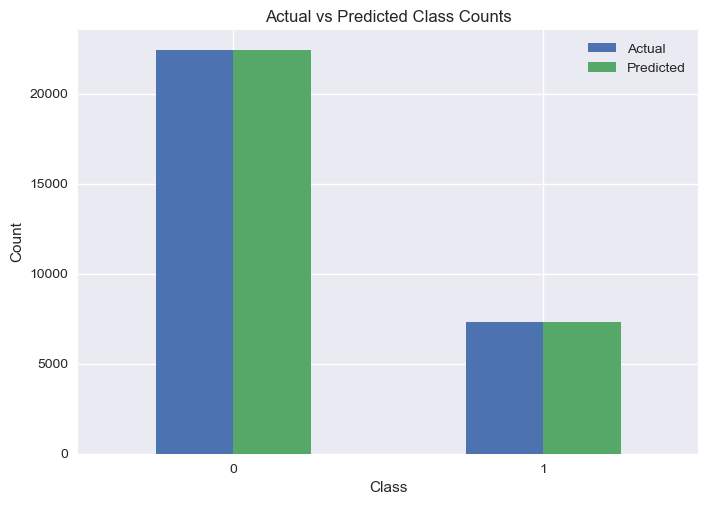

In [31]:
y_pred = (y_prob >= 0.20).astype(int)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
import matplotlib.pyplot as plt

import pandas as pd
import matplotlib.pyplot as plt

# predictions
y_pred = best_model.predict(X_test_xgb)

# dataframe
actual_vs_predicted = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

# count values
actual_counts = actual_vs_predicted["Actual"].value_counts().sort_index()
pred_counts = actual_vs_predicted["Predicted"].value_counts().sort_index()

# combine into one dataframe
comparison_df = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": pred_counts
}).fillna(0)

# plot
comparison_df.plot(kind="bar")
plt.title("Actual vs Predicted Class Counts")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

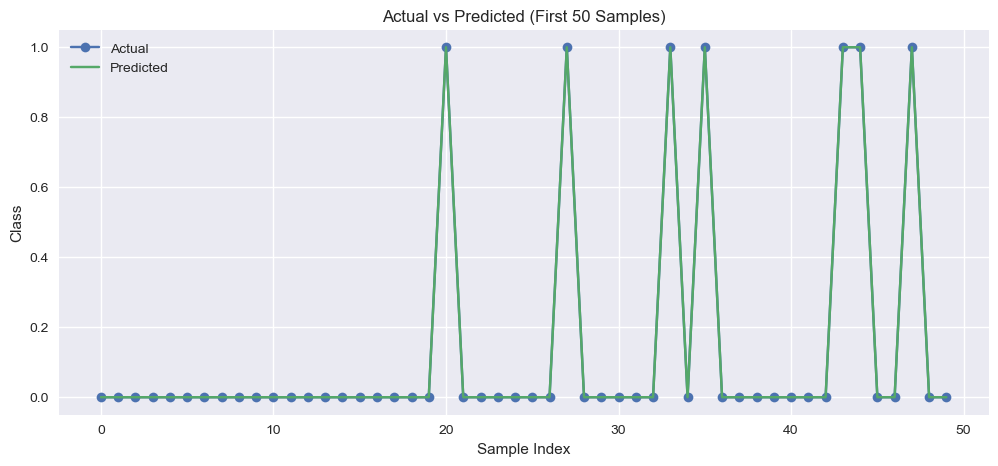

In [27]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_train, y_train)

print("Silhouette Score:", score)

Silhouette Score: -0.01896351605118398


In [20]:
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

threshold = 1.0
y_pred_xgb = (y_prob_xgb >= threshold).astype(int)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb, zero_division=0))
print("\nAccuracy  =", round(accuracy_score(y_test, y_pred_xgb), 3))
print("Precision =", round(precision_score(y_test, y_pred_xgb, zero_division=0), 3))
print("Recall    =", round(recall_score(y_test, y_pred_xgb, zero_division=0), 3))
print("F1-Score  =", round(f1_score(y_test, y_pred_xgb, zero_division=0), 3))
print("ROC-AUC   =", round(roc_auc_score(y_test, y_prob_xgb), 3))

NameError: name 'xgb_model' is not defined

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

thresholds = np.arange(0.0, 1.01, 0.01)
accuracy_list = []

for t in thresholds:
    y_pred = (y_prob_xgb >= t).astype(int)
    acc = accuracy_score(y_test, y_pred)
    accuracy_list.append([t, acc])

df_acc = pd.DataFrame(accuracy_list, columns=["Threshold", "Accuracy"])
print(df_acc)

In [38]:
for col in df.columns:
    if col != "status":
        try:
            match = (df[col].astype(str) == df["status"].astype(str)).mean()
            if match > 0.90:
                print(col, match)
        except:
            pass

In [39]:
print("status in X?", "status" in X.columns)
print(df.duplicated().sum())
print(df["status"].value_counts())

status in X? False
0
status
0    112031
1     36639
Name: count, dtype: int64


In [43]:
leak_cols = ["approv_in_adv", "credit_worthiness"]
X = df.drop(columns=["status"] + [c for c in leak_cols if c in df.columns], errors="ignore")
y = df["status"]

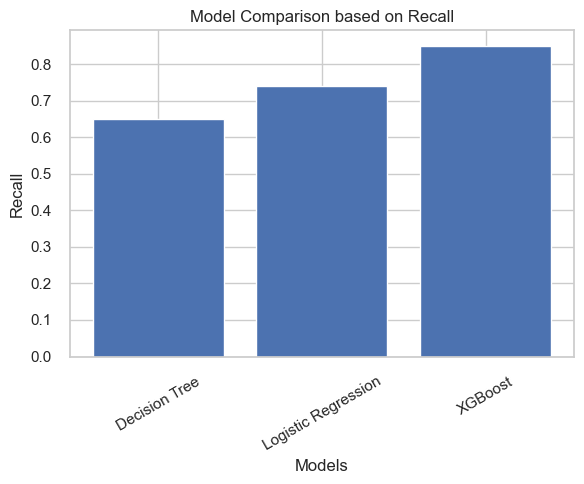

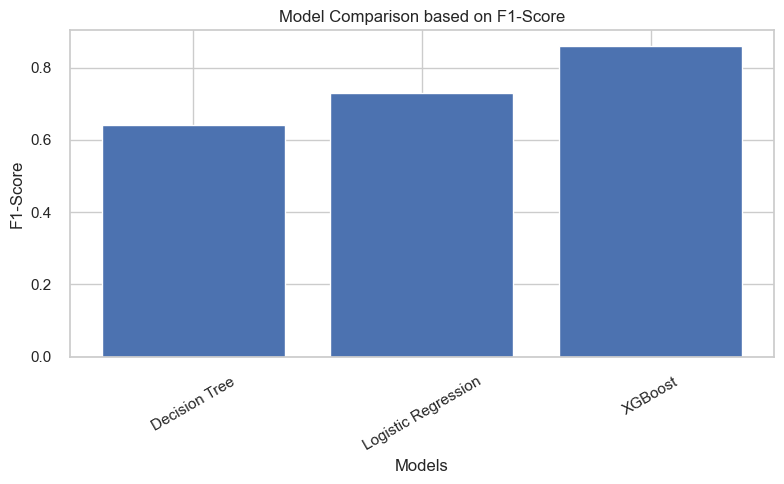

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Model comparison values
comparison_df = pd.DataFrame({
    "Model": ["Decision Tree", "Logistic Regression", "XGBoost"],
    "Recall": [0.65, 0.74, 0.85],
    "F1-Score": [0.64, 0.73, 0.86]
})

sns.set(style="whitegrid")

# Recall comparison
plt.figure(figsize=(6,5))
plt.bar(comparison_df["Model"], comparison_df["Recall"])
plt.title("Model Comparison based on Recall")
plt.xlabel("Models")
plt.ylabel("Recall")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# F1-Score comparison
plt.figure(figsize=(8,5))
plt.bar(comparison_df["Model"], comparison_df["F1-Score"])
plt.title("Model Comparison based on F1-Score")
plt.xlabel("Models")
plt.ylabel("F1-Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

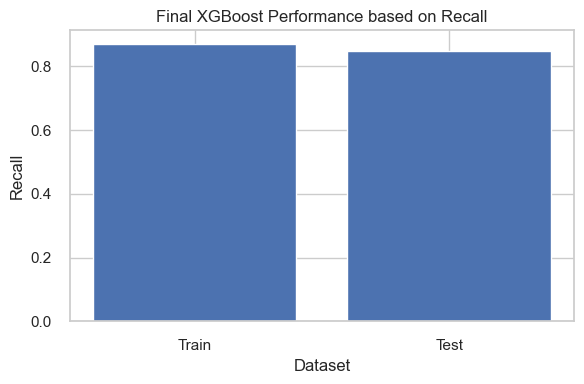

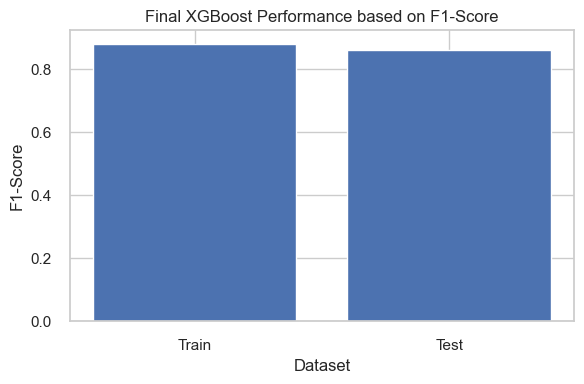

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

xgb_df = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Recall": [0.87, 0.85],
    "F1-Score": [0.88, 0.86]
})

sns.set(style="whitegrid")

# Recall
plt.figure(figsize=(6,4))
plt.bar(xgb_df["Dataset"], xgb_df["Recall"])
plt.title("Final XGBoost Performance based on Recall")
plt.xlabel("Dataset")
plt.ylabel("Recall")
plt.tight_layout()
plt.show()

# F1-Score
plt.figure(figsize=(6,4))
plt.bar(xgb_df["Dataset"], xgb_df["F1-Score"])
plt.title("Final XGBoost Performance based on F1-Score")
plt.xlabel("Dataset")
plt.ylabel("F1-Score")
plt.tight_layout()
plt.show()